<a href="https://www.kaggle.com/code/manahil12/telco-customer-churn-prediction-model-by-manahil?scriptVersionId=365562215" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


<div style="background-color: #000080; color: white; padding: 25px; text-align: center; border-radius: 10px; font-size:23px;">
    <h1 style="color: white; margin: 0; padding-bottom: 8px;">📊 Telco Customer Churn Prediction & Risk Factor Analysis</h1>
    <p style="margin: 0; font-size: 16px; font-weight: bold; text-align:right;">By: Manahil Tahir</p>
</div>

## 1. 🎯 Project Purpose
Customer churn (when a customer stops using a company's service) is one of the most critical financial metrics for telecommunications and SaaS companies. Acquiring new customers costs 5x more than retaining existing ones. 

The primary goal of this project is to build an end-to-end Machine Learning pipeline that:
1. **Predicts high-risk churn customers** before they cancel their service.
2. **Identifies key churn drivers** using SHAP (SHapley Additive exPlanations) so business strategy teams can take targeted retention actions.
3. **Optimizes business ROI** by balancing Precision and Recall to reduce costly false negatives.

## 2. Import and Setup

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc, roc_auc_score
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap

## 3. Data Loading

In [3]:
csv_path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if 'Telco' in file or 'WA_Fn-UseC_' in file:
            csv_path = os.path.join(root, file)
            break

if csv_path:
    print(f"✓ Successfully located dataset at: {csv_path}\n")
    df = pd.read_csv(csv_path)
    print(f"Dataset Shape: {df.shape}")
    print("\nClass Distribution (Counts):")
    print(df['Churn'].value_counts())
    print("\nClass Distribution (%):")
    print(df['Churn'].value_counts(normalize=True) * 100)
else:
    raise FileNotFoundError("Dataset not found. Please attach Telco Customer Churn from the right sidebar (+ Add Input).")

✓ Successfully located dataset at: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv

Dataset Shape: (7043, 21)

Class Distribution (Counts):
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Class Distribution (%):
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis (EDA) Visualizations

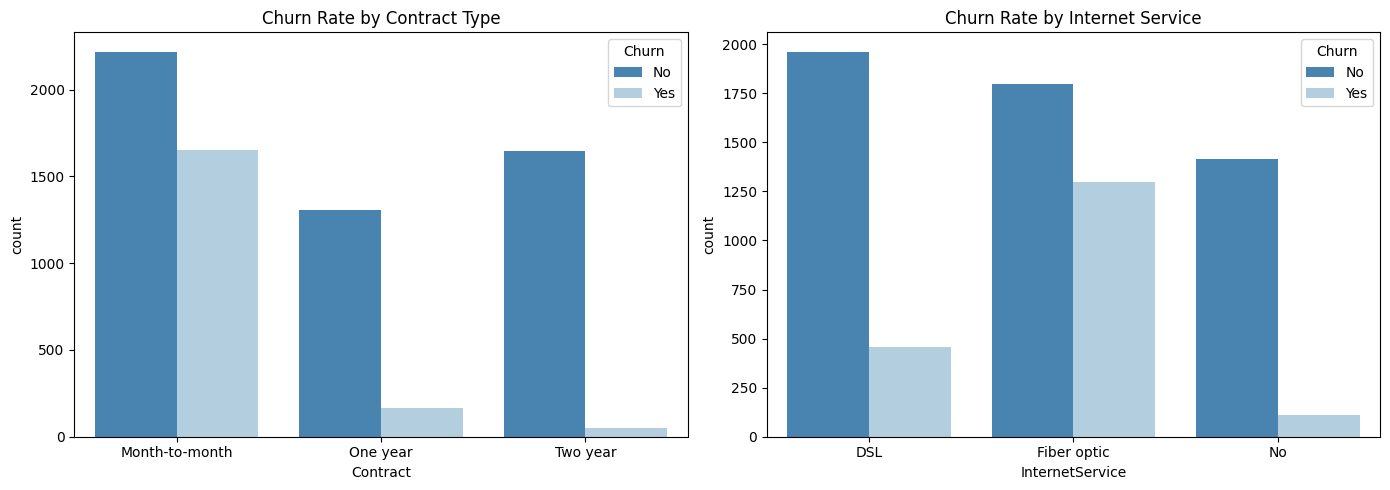

In [4]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Contract', hue='Churn', palette='Blues_r')
plt.title('Churn Rate by Contract Type', fontsize=12)

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Blues_r')
plt.title('Churn Rate by Internet Service', fontsize=12)

plt.tight_layout()
plt.show()

## 5. Data Cleaning & Preprocessing

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

df = pd.get_dummies(df, drop_first=True)

X = df.drop('Churn', axis=1)
y = df['Churn']

scaler = StandardScaler()
X[['tenure', 'MonthlyCharges', 'TotalCharges']] = scaler.fit_transform(X[['tenure', 'MonthlyCharges', 'TotalCharges']])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")
print(f"Training Churn Count: {y_train.sum()} ({y_train.mean()*100:.2f}%)")

Training set size: (5634, 30)
Test set size: (1409, 30)
Training Churn Count: 1495 (26.54%)


## 6. Class Imbalance Handling with SMOTE

In [6]:
smote = SMOTE(sampling_strategy=0.5, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Class distribution BEFORE SMOTE:")
print(y_train.value_counts().to_dict())

print("\nClass distribution AFTER SMOTE:")
print(pd.Series(y_train_res).value_counts().to_dict())

Class distribution BEFORE SMOTE:
{0: 4139, 1: 1495}

Class distribution AFTER SMOTE:
{0: 4139, 1: 2069}


## 7. Model Training (XGBoost Classifier)

In [7]:
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.08,
    scale_pos_weight=2,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

print("Training XGBoost Classifier...")
model.fit(X_train_res, y_train_res)
print("✓ Model training completed successfully.")

Training XGBoost Classifier...
✓ Model training completed successfully.


## 8. Model Evaluation & PR-AUC Calculation

             MODEL EVALUATION
PR-AUC Score  : 0.6562
ROC-AUC Score : 0.8433

              precision    recall  f1-score   support

Retained (0)       0.90      0.77      0.83      1035
 Churned (1)       0.54      0.76      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409



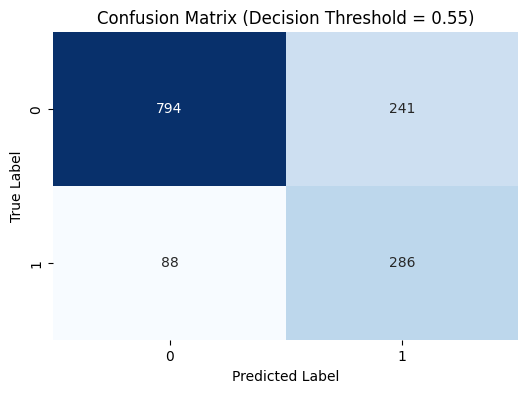

In [8]:
y_pred_proba = model.predict_proba(X_test)[:, 1]

threshold = 0.55
y_pred_custom = (y_pred_proba >= threshold).astype(int)

precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall_vals, precision_vals)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=" * 45)
print("             MODEL EVALUATION")
print("=" * 45)
print(f"PR-AUC Score  : {pr_auc:.4f}")
print(f"ROC-AUC Score : {roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_custom, target_names=['Retained (0)', 'Churned (1)']))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_custom), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix (Decision Threshold = {threshold})', fontsize=12)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## 9. Model Explainability with SHAP

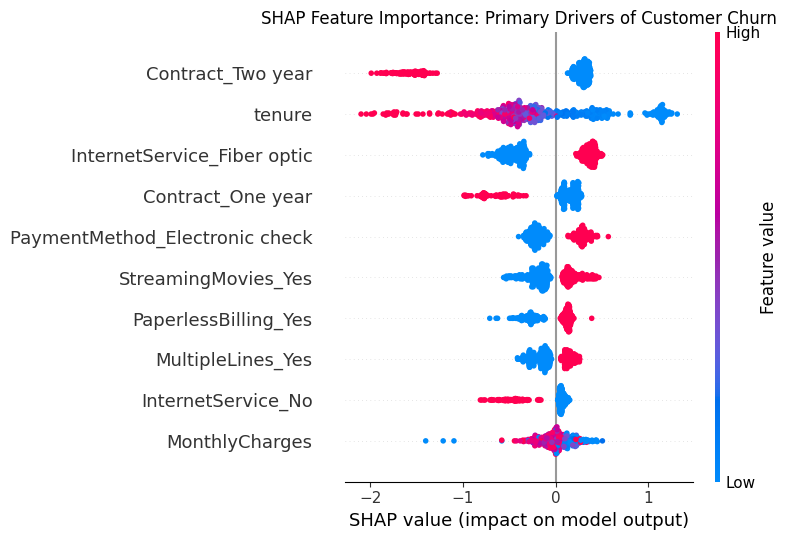

In [9]:
X_test_sample = X_test.sample(500, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_sample)

plt.figure(figsize=(20, 10))
plt.title("SHAP Feature Importance: Primary Drivers of Customer Churn", fontsize=12)
shap.summary_plot(shap_values, X_test_sample, max_display=10, show=False)
plt.tight_layout()
plt.show()